In [2]:
# ============================================================
# Notebook 2: Adversarial Attacks
# We will implement FGSM, PGD, and C&W attacks
# Goal: fool our trained models with invisible perturbations
# ============================================================

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# ── Rebuild the SimpleCNN architecture (same as notebook 1) ──
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.relu  = nn.ReLU()
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# ── Load the saved MNIST model from disk ──
mnist_model = SimpleCNN()
mnist_model.load_state_dict(
    torch.load('../models/mnist_cnn_baseline.pth', weights_only=True)
)
mnist_model.eval()  # evaluation mode — no dropout
print("MNIST model loaded successfully!")

# ── Reload MNIST test data ──
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

test_dataset = torchvision.datasets.MNIST(
    root='../data', train=False, download=False, transform=transform
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=64, shuffle=False
)

print(f"Test images loaded: {len(test_dataset)}")
print("\nReady to attack!")

MNIST model loaded successfully!
Test images loaded: 10000

Ready to attack!


Testing FGSM attack at different strengths...

Epsilon=0.00 → Accuracy: 99.09%  (Attack success: 0.91%)
Epsilon=0.05 → Accuracy: 97.49%  (Attack success: 2.51%)
Epsilon=0.10 → Accuracy: 95.03%  (Attack success: 4.97%)
Epsilon=0.20 → Accuracy: 85.44%  (Attack success: 14.56%)
Epsilon=0.30 → Accuracy: 68.87%  (Attack success: 31.13%)
Epsilon=0.50 → Accuracy: 34.97%  (Attack success: 65.03%)


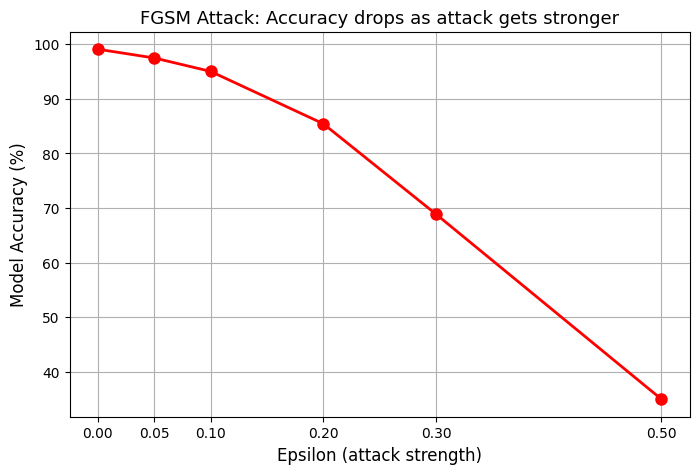


FGSM accuracy plot saved!


In [2]:
# CELL 2 - FGSM Attack (Fast Gradient Sign Method)
# Invented by Goodfellow et al. 2015 (one of your literature review papers!)
#
# HOW IT WORKS (simple explanation):
# 1. Feed an image to the model
# 2. Calculate the loss (how wrong the model is)
# 3. Calculate gradients (which direction makes loss increase)
# 4. Add a tiny amount of noise IN that direction
# 5. The model gets confused and misclassifies the image
# The noise is so small humans cannot see it!

def fgsm_attack(model, images, labels, epsilon):
    """
    model   : the trained neural network
    images  : input images to attack
    labels  : correct labels for those images
    epsilon : attack strength (how much noise to add)
              small = invisible but weak, large = visible but strong
    """
    # Tell PyTorch we need gradients for the images
    images.requires_grad = True

    # Forward pass — get model predictions
    outputs = model(images)
    loss = nn.CrossEntropyLoss()(outputs, labels)

    # Backward pass — calculate gradients
    model.zero_grad()
    loss.backward()

    # Get the sign of each gradient (+1 or -1)
    gradient_sign = images.grad.data.sign()

    # Add noise in the gradient direction
    adversarial_images = images + epsilon * gradient_sign

    # Clip to keep pixel values in valid range [-1, 1]
    adversarial_images = torch.clamp(adversarial_images, -1, 1)

    return adversarial_images.detach()


# Test FGSM at different epsilon (strength) values
epsilons = [0, 0.05, 0.1, 0.2, 0.3, 0.5]
fgsm_accuracies = []

print("Testing FGSM attack at different strengths...\n")

for eps in epsilons:
    correct = 0
    total = 0

    for images, labels in test_loader:
        if eps == 0:
            # No attack — just measure clean accuracy
            with torch.no_grad():
                outputs = model(images) if False else mnist_model(images)
                _, predicted = outputs.max(1)
        else:
            # Apply FGSM attack
            adv_images = fgsm_attack(mnist_model, images, labels, eps)
            with torch.no_grad():
                outputs = mnist_model(adv_images)
                _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    acc = 100. * correct / total
    fgsm_accuracies.append(acc)
    print(f"Epsilon={eps:.2f} → Accuracy: {acc:.2f}%  "
          f"(Attack success: {100-acc:.2f}%)")

# Plot accuracy vs epsilon
plt.figure(figsize=(8, 5))
plt.plot(epsilons, fgsm_accuracies, 'r-o', linewidth=2, markersize=8)
plt.xlabel('Epsilon (attack strength)', fontsize=12)
plt.ylabel('Model Accuracy (%)', fontsize=12)
plt.title('FGSM Attack: Accuracy drops as attack gets stronger', fontsize=13)
plt.grid(True)
plt.xticks(epsilons)
plt.savefig('../figures/fgsm_accuracy_vs_epsilon.png')
plt.show()
print("\nFGSM accuracy plot saved!")

Visualizing FGSM attacks at epsilon=0.3...



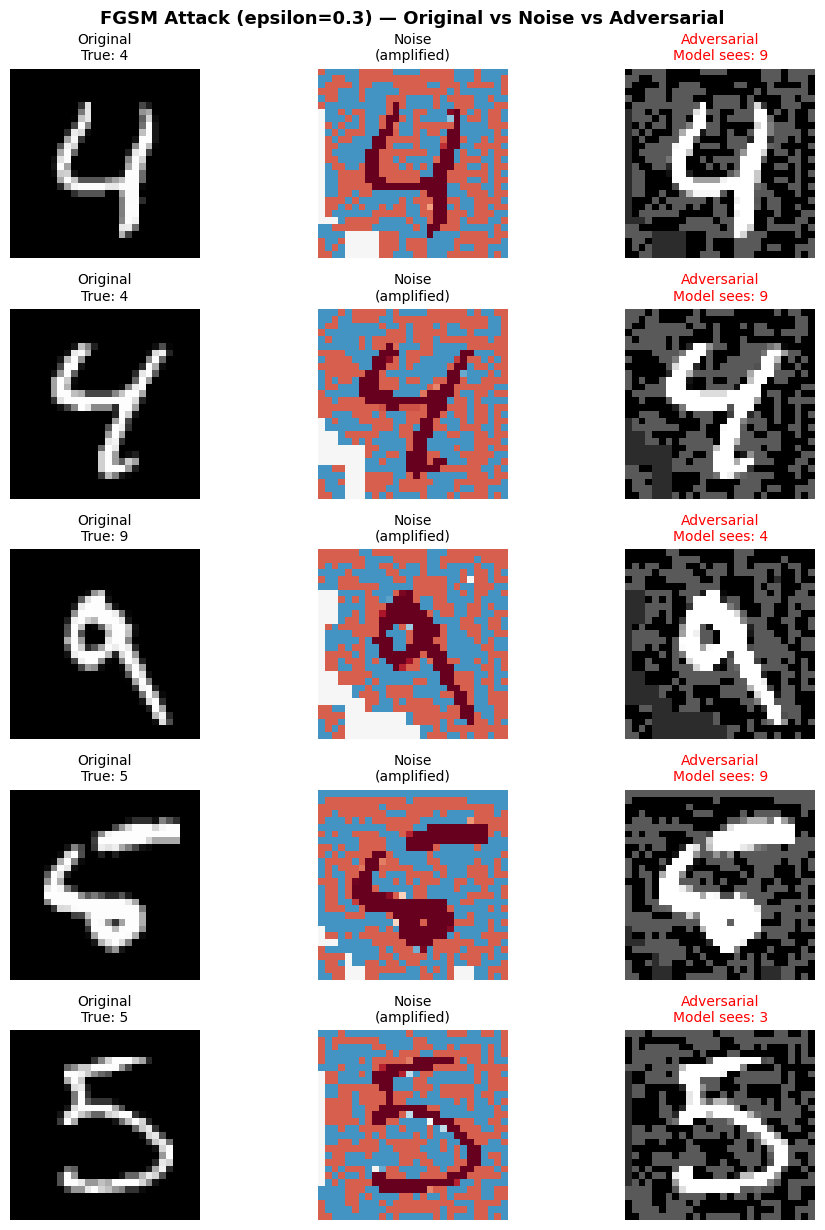

Saved: figures/fgsm_examples_eps0.3.png

FGSM results saved to results/fgsm_results.txt


In [6]:
# CELL 3 - Visualize adversarial examples (fixed)

def visualize_fgsm(model, test_loader, epsilon, num_images=5):
    model.eval()

    images_shown = 0
    originals, adversarials, orig_labels, orig_preds, adv_preds = [], [], [], [], []

    for images, labels in test_loader:
        if images_shown >= num_images:
            break

        with torch.no_grad():
            clean_out = model(images)
            _, clean_pred = clean_out.max(1)

        adv_images = fgsm_attack(model, images, labels, epsilon)

        with torch.no_grad():
            adv_out = model(adv_images)
            _, adv_pred = adv_out.max(1)

        for i in range(len(labels)):
            if images_shown >= num_images:
                break
            if clean_pred[i] == labels[i] and adv_pred[i] != labels[i]:
                # .detach() added here — this was the fix
                originals.append(images[i].squeeze().detach().numpy())
                adversarials.append(adv_images[i].squeeze().detach().numpy())
                orig_labels.append(labels[i].item())
                orig_preds.append(clean_pred[i].item())
                adv_preds.append(adv_pred[i].item())
                images_shown += 1

    if images_shown == 0:
        print("No successful attacks found. Try higher epsilon.")
        return

    fig, axes = plt.subplots(images_shown, 3, figsize=(10, 2.5 * images_shown))
    fig.suptitle(f'FGSM Attack (epsilon={epsilon}) — Original vs Noise vs Adversarial',
                 fontsize=13, fontweight='bold')

    for i in range(images_shown):
        noise = adversarials[i] - originals[i]

        axes[i, 0].imshow(originals[i], cmap='gray')
        axes[i, 0].set_title(f'Original\nTrue: {orig_labels[i]}', fontsize=10)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(noise, cmap='RdBu', vmin=-0.5, vmax=0.5)
        axes[i, 1].set_title('Noise\n(amplified)', fontsize=10)
        axes[i, 1].axis('off')

        axes[i, 2].imshow(adversarials[i], cmap='gray')
        axes[i, 2].set_title(f'Adversarial\nModel sees: {adv_preds[i]}',
                              fontsize=10, color='red')
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.savefig(f'../figures/fgsm_examples_eps{epsilon}.png', dpi=150)
    plt.show()
    print(f"Saved: figures/fgsm_examples_eps{epsilon}.png")


print("Visualizing FGSM attacks at epsilon=0.3...\n")
visualize_fgsm(mnist_model, test_loader, epsilon=0.3)

with open('../results/fgsm_results.txt', 'w') as f:
    f.write("FGSM Attack Results on MNIST\n")
    f.write("=" * 40 + "\n")
    for eps, acc in zip(epsilons, fgsm_accuracies):
        f.write(f"Epsilon={eps:.2f}: Accuracy={acc:.2f}%  "
                f"Attack success={100-acc:.2f}%\n")

print("\nFGSM results saved to results/fgsm_results.txt")

Comparing FGSM vs PGD attack...



Testing both attacks: 100%|██████████████████████████████████████████████████████████| 157/157 [02:19<00:00,  1.13it/s]



At epsilon=0.3:
  Clean accuracy  : 99.09%
  FGSM accuracy   : 68.87%  (attack success: 31.13%)
  PGD accuracy    : 31.53%   (attack success: 68.47%)

PGD is 37.34% more effective than FGSM!


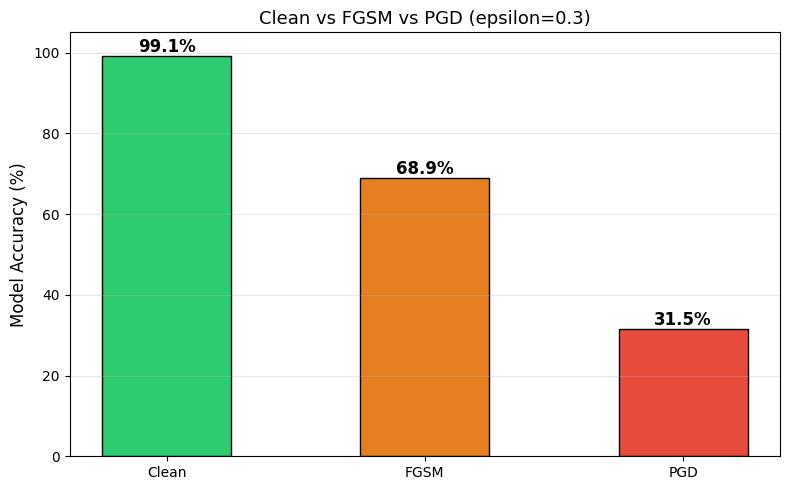


PGD results saved!


In [7]:
# CELL 4 - PGD Attack (Projected Gradient Descent)
# Invented by Madry et al. 2018 (another one of your literature papers!)
#
# HOW IT WORKS:
# FGSM takes ONE big step in the gradient direction
# PGD takes MANY small steps, adjusting direction each time
# This makes it much stronger — like a persistent attacker
# who keeps trying different angles until they find a weakness

def pgd_attack(model, images, labels, epsilon, alpha, num_steps):
    """
    epsilon   : maximum total perturbation allowed
    alpha     : step size per iteration (small steps)
    num_steps : how many iterations to run
    """
    # Start with a random small perturbation
    adv_images = images.clone().detach()
    adv_images = adv_images + torch.empty_like(adv_images).uniform_(-epsilon, epsilon)
    adv_images = torch.clamp(adv_images, -1, 1).detach()

    for step in range(num_steps):
        adv_images.requires_grad = True

        outputs = model(adv_images)
        loss = nn.CrossEntropyLoss()(outputs, labels)

        model.zero_grad()
        loss.backward()

        # Take one small step in gradient direction
        adv_images = adv_images + alpha * adv_images.grad.sign()

        # Project back into the epsilon ball around original image
        # This ensures we don't stray too far from the original
        perturbation = torch.clamp(adv_images - images, -epsilon, epsilon)
        adv_images = torch.clamp(images + perturbation, -1, 1).detach()

    return adv_images


# Compare FGSM vs PGD at same epsilon
epsilon = 0.3
alpha = 0.01      # step size
num_steps = 40    # number of iterations

print("Comparing FGSM vs PGD attack...\n")

# Measure FGSM accuracy at epsilon=0.3
fgsm_correct = 0
pgd_correct = 0
total = 0

for images, labels in tqdm(test_loader, desc="Testing both attacks"):
    # FGSM
    adv_fgsm = fgsm_attack(mnist_model, images, labels, epsilon)
    with torch.no_grad():
        _, fgsm_pred = mnist_model(adv_fgsm).max(1)
        fgsm_correct += fgsm_pred.eq(labels).sum().item()

    # PGD
    adv_pgd = pgd_attack(mnist_model, images, labels, epsilon, alpha, num_steps)
    with torch.no_grad():
        _, pgd_pred = mnist_model(adv_pgd).max(1)
        pgd_correct += pgd_pred.eq(labels).sum().item()

    total += labels.size(0)

fgsm_acc = 100. * fgsm_correct / total
pgd_acc  = 100. * pgd_correct  / total

print(f"\nAt epsilon={epsilon}:")
print(f"  Clean accuracy  : 99.09%")
print(f"  FGSM accuracy   : {fgsm_acc:.2f}%  (attack success: {100-fgsm_acc:.2f}%)")
print(f"  PGD accuracy    : {pgd_acc:.2f}%   (attack success: {100-pgd_acc:.2f}%)")
print(f"\nPGD is {fgsm_acc - pgd_acc:.2f}% more effective than FGSM!")

# Bar chart comparison
fig, ax = plt.subplots(figsize=(8, 5))
attacks = ['Clean', 'FGSM', 'PGD']
accuracies = [99.09, fgsm_acc, pgd_acc]
colors = ['#2ecc71', '#e67e22', '#e74c3c']

bars = ax.bar(attacks, accuracies, color=colors, width=0.5, edgecolor='black')
ax.set_ylabel('Model Accuracy (%)', fontsize=12)
ax.set_title(f'Clean vs FGSM vs PGD (epsilon={epsilon})', fontsize=13)
ax.set_ylim(0, 105)
ax.grid(axis='y', alpha=0.3)

for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{acc:.1f}%', ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/fgsm_vs_pgd_comparison.png', dpi=150)
plt.show()

# Save results
with open('../results/pgd_results.txt', 'w') as f:
    f.write("PGD Attack Results on MNIST\n")
    f.write("=" * 40 + "\n")
    f.write(f"Epsilon: {epsilon}, Alpha: {alpha}, Steps: {num_steps}\n\n")
    f.write(f"Clean accuracy : 99.09%\n")
    f.write(f"FGSM accuracy  : {fgsm_acc:.2f}%\n")
    f.write(f"PGD accuracy   : {pgd_acc:.2f}%\n")

print("\nPGD results saved!")

Label Flipping Poisoning Attack
Flipping '9' labels → '4'

Poisoning 0/5949 '9' labels → '4'
Poison rate=0%: Overall=99.1%  Accuracy on '9'=98.6%
Poisoning 594/5949 '9' labels → '4'
Poison rate=10%: Overall=99.0%  Accuracy on '9'=98.0%
Poisoning 1189/5949 '9' labels → '4'
Poison rate=20%: Overall=99.1%  Accuracy on '9'=97.7%
Poisoning 2974/5949 '9' labels → '4'
Poison rate=50%: Overall=89.3%  Accuracy on '9'=0.5%
Poisoning 5949/5949 '9' labels → '4'
Poison rate=100%: Overall=89.2%  Accuracy on '9'=0.0%


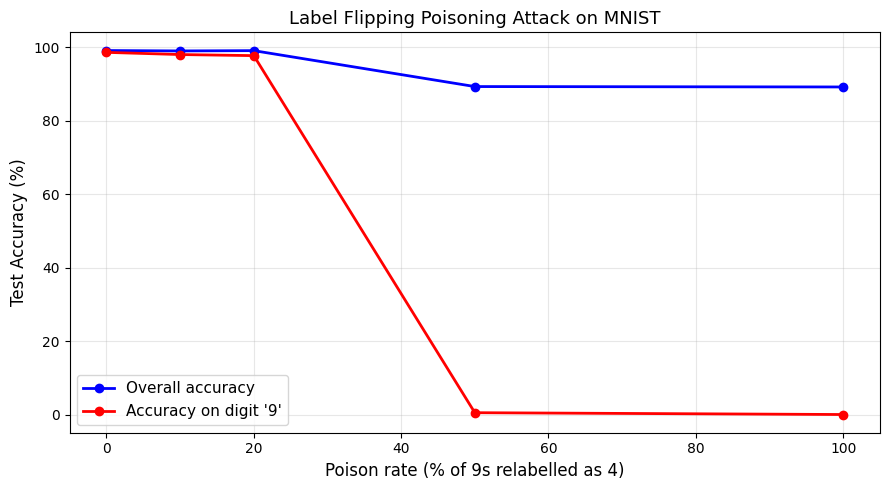


Poisoning results saved!


In [3]:
# CELL 5 - Data Poisoning Attack (Label Flipping)
# 
# HOW IT WORKS:
# Instead of attacking at inference time (like FGSM/PGD),
# poisoning attacks corrupt the TRAINING DATA before the model learns
# 
# Label flipping: change correct labels to wrong ones
# Example: relabel all "9"s as "4"s in training data
# The model then learns the WRONG associations
# Real-world risk: an attacker who can modify training data
# can silently degrade your model before it's even deployed

import copy
from torch.utils.data import Dataset

class PoisonedMNIST(Dataset):
    """MNIST dataset with some labels flipped"""
    def __init__(self, dataset, poison_rate, source_class, target_class):
        """
        poison_rate  : fraction of source_class to mislabel (0.0 to 1.0)
        source_class : the class we poison (e.g. 9)
        target_class : what we change it to (e.g. 4)
        """
        self.dataset = dataset
        self.poison_rate = poison_rate
        self.source_class = source_class
        self.target_class = target_class

        # Find all indices of source_class
        self.poisoned_indices = set()
        source_indices = [i for i, (_, label) in enumerate(dataset)
                         if label == source_class]

        # Randomly select poison_rate fraction to flip
        num_to_poison = int(len(source_indices) * poison_rate)
        poisoned = np.random.choice(source_indices, num_to_poison, replace=False)
        self.poisoned_indices = set(poisoned)

        print(f"Poisoning {num_to_poison}/{len(source_indices)} "
              f"'{source_class}' labels → '{target_class}'")

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]
        # Return flipped label if this index was poisoned
        if idx in self.poisoned_indices:
            label = self.target_class
        return image, label


# Reload clean training data
clean_train = torchvision.datasets.MNIST(
    root='../data', train=True, download=False, transform=transform
)

# Test different poison rates
poison_rates = [0.0, 0.1, 0.2, 0.5, 1.0]
source_class = 9   # we poison the digit "9"
target_class = 4   # relabel them as "4"

poison_results = []

print("="*50)
print("Label Flipping Poisoning Attack")
print(f"Flipping '{source_class}' labels → '{target_class}'")
print("="*50 + "\n")

for rate in poison_rates:
    # Create poisoned dataset
    poisoned_train = PoisonedMNIST(clean_train, rate, source_class, target_class)
    poisoned_loader = torch.utils.data.DataLoader(
        poisoned_train, batch_size=64, shuffle=True
    )

    # Train a fresh model on poisoned data
    poisoned_model = SimpleCNN()
    optimizer = torch.optim.Adam(poisoned_model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # Train for 3 epochs
    for epoch in range(3):
        poisoned_model.train()
        for images, labels in poisoned_loader:
            optimizer.zero_grad()
            loss = criterion(poisoned_model(images), labels)
            loss.backward()
            optimizer.step()

    # Evaluate on CLEAN test data
    poisoned_model.eval()
    correct = 0
    total = 0
    class9_correct = 0
    class9_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = poisoned_model(images)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            # Track specifically how well it classifies "9"
            mask = labels == source_class
            if mask.sum() > 0:
                class9_total += mask.sum().item()
                class9_correct += predicted[mask].eq(labels[mask]).sum().item()

    overall_acc = 100. * correct / total
    class9_acc = 100. * class9_correct / class9_total if class9_total > 0 else 0
    poison_results.append((rate, overall_acc, class9_acc))

    print(f"Poison rate={rate:.0%}: Overall={overall_acc:.1f}%  "
          f"Accuracy on '{source_class}'={class9_acc:.1f}%")

# Plot results
rates = [r[0]*100 for r in poison_results]
overall_accs = [r[1] for r in poison_results]
class9_accs  = [r[2] for r in poison_results]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rates, overall_accs, 'b-o', linewidth=2, label='Overall accuracy')
ax.plot(rates, class9_accs,  'r-o', linewidth=2, label=f"Accuracy on digit '{source_class}'")
ax.set_xlabel('Poison rate (% of 9s relabelled as 4)', fontsize=12)
ax.set_ylabel('Test Accuracy (%)', fontsize=12)
ax.set_title('Label Flipping Poisoning Attack on MNIST', fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/poisoning_label_flip.png', dpi=150)
plt.show()

# Save results
with open('../results/poisoning_results.txt', 'w') as f:
    f.write("Label Flipping Poisoning Attack Results\n")
    f.write("=" * 40 + "\n")
    f.write(f"Source class: {source_class}, Target class: {target_class}\n\n")
    for rate, oacc, cacc in poison_results:
        f.write(f"Poison rate={rate:.0%}: Overall={oacc:.1f}%  "
                f"Class-{source_class} accuracy={cacc:.1f}%\n")

print("\nPoisoning results saved!")

Membership Inference Attack
Question: Can an attacker tell if a sample was in the training set?

Getting confidence scores for training data (members)...
Getting confidence scores for test data (non-members)...

Average confidence on TRAINING data: 0.9930
Average confidence on TEST data:     0.9891
Confidence gap: 0.0039

Membership Inference Results (threshold=0.95):
  True positive rate  : 97.10% (members correctly identified)
  False positive rate : 95.80% (non-members wrongly flagged)
  Attack accuracy     : 96.5%
  Random baseline     : 50.0%
  Advantage over random: +46.5%


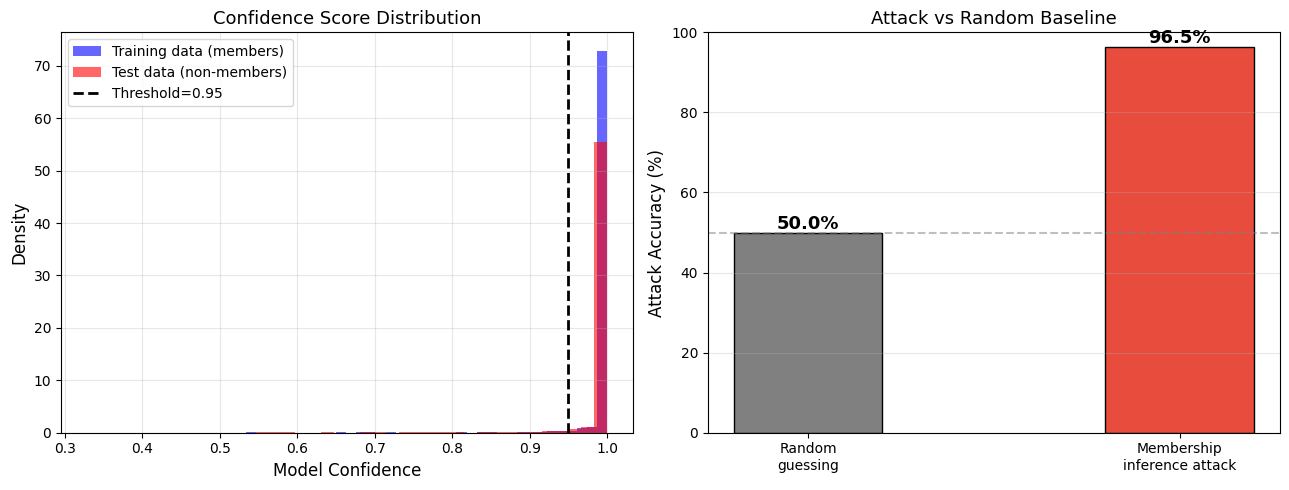


Membership inference results saved!


In [4]:
# CELL 6 - Membership Inference Attack
#
# HOW IT WORKS:
# The attacker asks: "Was this specific data point used to train the model?"
# 
# Key insight: Models are usually MORE confident on training data
# than on data they've never seen (they tend to "memorise" training examples)
# 
# Attack strategy:
# - If model confidence is HIGH → guess "this was in training data"
# - If model confidence is LOW  → guess "this was NOT in training data"
# 
# Real-world risk: Privacy leak — attacker can determine if
# a specific person's medical record was used to train a medical AI

print("Membership Inference Attack")
print("="*50)
print("Question: Can an attacker tell if a sample was in the training set?\n")

# Load training data (these WERE used to train our model)
train_dataset_small = torchvision.datasets.MNIST(
    root='../data', train=True, download=False, transform=transform
)

# Use first 2000 training samples as "members"
member_loader = torch.utils.data.DataLoader(
    torch.utils.data.Subset(train_dataset_small, range(2000)),
    batch_size=64, shuffle=False
)

# Use first 2000 test samples as "non-members"
non_member_loader = torch.utils.data.DataLoader(
    torch.utils.data.Subset(test_dataset, range(2000)),
    batch_size=64, shuffle=False
)

def get_confidence_scores(model, loader):
    """Get the model's maximum confidence score for each image"""
    model.eval()
    confidences = []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images)
            # Softmax converts raw scores to probabilities (sum to 1)
            probs = torch.softmax(outputs, dim=1)
            # Max confidence = how sure the model is about its top prediction
            max_conf, _ = probs.max(dim=1)
            confidences.extend(max_conf.numpy())
    return np.array(confidences)

# Get confidence scores for members and non-members
print("Getting confidence scores for training data (members)...")
member_confidences = get_confidence_scores(mnist_model, member_loader)

print("Getting confidence scores for test data (non-members)...")
non_member_confidences = get_confidence_scores(mnist_model, non_member_loader)

print(f"\nAverage confidence on TRAINING data: {member_confidences.mean():.4f}")
print(f"Average confidence on TEST data:     {non_member_confidences.mean():.4f}")
print(f"Confidence gap: {member_confidences.mean() - non_member_confidences.mean():.4f}")

# Simple threshold attack: classify as member if confidence > threshold
threshold = 0.95
member_predictions    = (member_confidences > threshold).astype(int)
nonmember_predictions = (non_member_confidences > threshold).astype(int)

true_positive_rate  = member_predictions.mean()       # correctly identified members
false_positive_rate = nonmember_predictions.mean()    # non-members wrongly called members

# Attack accuracy (random guessing = 50%)
all_labels = np.concatenate([np.ones(2000), np.zeros(2000)])
all_preds  = np.concatenate([member_predictions, 1 - nonmember_predictions])
attack_acc = (all_labels == all_preds).mean() * 100

print(f"\nMembership Inference Results (threshold={threshold}):")
print(f"  True positive rate  : {true_positive_rate:.2%} (members correctly identified)")
print(f"  False positive rate : {false_positive_rate:.2%} (non-members wrongly flagged)")
print(f"  Attack accuracy     : {attack_acc:.1f}%")
print(f"  Random baseline     : 50.0%")
print(f"  Advantage over random: +{attack_acc-50:.1f}%")

# Plot confidence distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram of confidence scores
axes[0].hist(member_confidences, bins=40, alpha=0.6, color='blue',
             label='Training data (members)', density=True)
axes[0].hist(non_member_confidences, bins=40, alpha=0.6, color='red',
             label='Test data (non-members)', density=True)
axes[0].axvline(x=threshold, color='black', linestyle='--',
                linewidth=2, label=f'Threshold={threshold}')
axes[0].set_xlabel('Model Confidence', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)
axes[0].set_title('Confidence Score Distribution', fontsize=13)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Bar chart summary
axes[1].bar(['Random\nguessing', 'Membership\ninference attack'],
            [50, attack_acc],
            color=['gray', '#e74c3c'], width=0.4, edgecolor='black')
axes[1].set_ylabel('Attack Accuracy (%)', fontsize=12)
axes[1].set_title('Attack vs Random Baseline', fontsize=13)
axes[1].set_ylim(0, 100)
axes[1].axhline(y=50, color='gray', linestyle='--', alpha=0.5)
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate([50, attack_acc]):
    axes[1].text(i, v + 1, f'{v:.1f}%', ha='center',
                 fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../figures/membership_inference.png', dpi=150)
plt.show()

# Save results
with open('../results/membership_inference_results.txt', 'w') as f:
    f.write("Membership Inference Attack Results\n")
    f.write("=" * 40 + "\n")
    f.write(f"Threshold: {threshold}\n")
    f.write(f"Members avg confidence    : {member_confidences.mean():.4f}\n")
    f.write(f"Non-members avg confidence: {non_member_confidences.mean():.4f}\n")
    f.write(f"Attack accuracy           : {attack_acc:.1f}%\n")
    f.write(f"Random baseline           : 50.0%\n")

print("\nMembership inference results saved!")